<a href="https://colab.research.google.com/github/JosueTP249/Tareas_SistemasInteligentes/blob/main/Tarea02_Fashion_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea 02 - Introducción a visión computacional



## 1. Importar librerías

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.metrics import ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
print("GPUs disponibles:", len(gpus))

I0000 00:00:1794540062.702363    1697 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794540062.734221    1697 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 AMX_FP16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794540063.756553    1697 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPUs disponibles: 0


## 2. Cargar el dataset
Se usa el `tfds.load` de la tarea.
Con `batch_size=32`, `tfds` ya entrega los datos agrupados en lotes de 32 imágenes.

In [ ]:
train_ds, val_ds, test_ds = tfds.load(
    'fashion_mnist',
    split=['train[:90%]', 'train[90%:]', 'test'],
    shuffle_files=True,
    as_supervised=True,
    batch_size=32,
)

print(train_ds.element_spec)

(TensorSpec(shape=(None, 28, 28, 1), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))


In [ ]:
# Contar muestras
for nombre, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    n = sum(int(x.shape[0]) for x, _ in ds)
    print(f"{nombre}: {n} imágenes")

train: 54000 imágenes
val: 6000 imágenes
test: 10000 imágenes


## 3. Explorar los datos

Forma de un lote: (32, 28, 28, 1) | tipo: <dtype: 'uint8'>
Valores de píxel: mín 0 máx 255


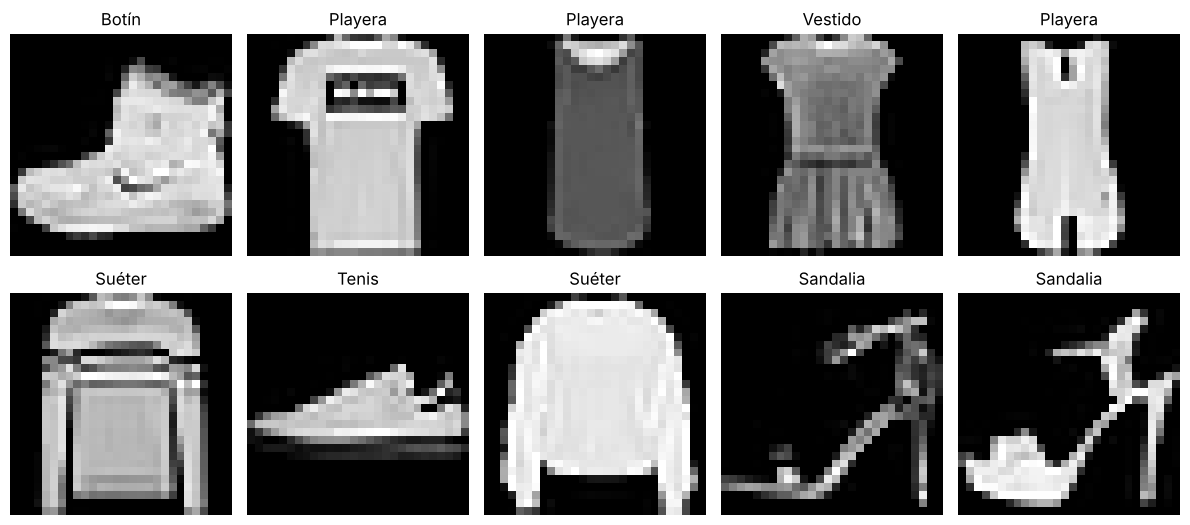

In [ ]:
nombres_clases = ["Playera", "Pantalón", "Suéter", "Vestido", "Abrigo",
                  "Sandalia", "Camisa", "Tenis", "Bolsa", "Botín"]

imagenes, etiquetas = next(iter(train_ds))
print("Forma de un lote:", imagenes.shape, "| tipo:", imagenes.dtype)
print("Valores de píxel: mín", imagenes.numpy().min(), "máx", imagenes.numpy().max())

fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(imagenes[i, :, :, 0], cmap="gray")
    ax.set_title(nombres_clases[int(etiquetas[i])])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Preprocesamiento


In [ ]:
def normalizar(imagen, etiqueta):
    return tf.cast(imagen, tf.float32) / 255.0, etiqueta

# 54,000 imágenes / 32 por lote = 1,688 lotes (unbatch hace que TensorFlow pierda el conteo, así que se lo indicamos)
LOTES_TRAIN = 1688

train_ds = (train_ds.map(normalizar)
            .unbatch().shuffle(10_000).batch(32)
            .apply(tf.data.experimental.assert_cardinality(LOTES_TRAIN))
            .prefetch(tf.data.AUTOTUNE))
val_ds = val_ds.map(normalizar).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.map(normalizar).prefetch(tf.data.AUTOTUNE)

## 5. Funciones auxiliares
- `construir_modelo`: arma la red con `Flatten`, capas ocultas y una **capa de 2 neuronas (`rep_2d`)** que permite graficar en 2D.
- `plot_learning_curve`: la misma que usamos en clase.

In [ ]:
def construir_modelo(capas_ocultas, activacion="relu", dropout=0.0, optimizador="adam"):
    capas = [
        tf.keras.layers.Input(shape=(28, 28, 1)),
        tf.keras.layers.Flatten(),
    ]
    for unidades in capas_ocultas:
        capas.append(tf.keras.layers.Dense(unidades, activation=activacion))
        if dropout > 0:
            capas.append(tf.keras.layers.Dropout(dropout))

    capas.append(tf.keras.layers.Dense(2, activation="linear", name="rep_2d"))  # espacio latente 2D
    capas.append(tf.keras.layers.Dense(10, activation="softmax"))

    modelo = tf.keras.Sequential(capas)
    modelo.compile(
        optimizer=optimizador,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return modelo


def plot_learning_curve(history, titulo=""):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(history.history["accuracy"], label="Training accuracy")
    ax[0].plot(history.history["val_accuracy"], label="Validation accuracy")
    ax[0].set_title(f"Accuracy {titulo}"); ax[0].set_xlabel("Época"); ax[0].legend()
    ax[1].plot(history.history["loss"], label="Training loss")
    ax[1].plot(history.history["val_loss"], label="Validation loss")
    ax[1].set_title(f"Loss {titulo}"); ax[1].set_xlabel("Época"); ax[1].legend()
    plt.tight_layout()
    plt.show()

## 6. Tres configuraciones


In [ ]:
configuraciones = {
    "A: 128":                  dict(capas_ocultas=[128]),
    "B: 256-128":              dict(capas_ocultas=[256, 128]),
    "C: 256-128 + Dropout 0.3": dict(capas_ocultas=[256, 128], dropout=0.3),
}

modelos, historiales, resultados = {}, {}, []

for nombre, cfg in configuraciones.items():
    print(f"\n=== Entrenando configuración {nombre} ===")
    modelo = construir_modelo(**cfg)

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True)

    historia = modelo.fit(train_ds, validation_data=val_ds,
                          epochs=25, callbacks=[early_stop],
                          shuffle=False, verbose=0)  # el shuffle ya lo hace tf.data

    mejor_epoca = int(np.argmin(historia.history["val_loss"]))  # época cuyos pesos se restauraron
    _, val_acc = modelo.evaluate(val_ds, verbose=0)
    _, test_acc = modelo.evaluate(test_ds, verbose=0)

    modelos[nombre], historiales[nombre] = modelo, historia
    resultados.append({
        "Configuración": nombre,
        "Parámetros": modelo.count_params(),
        "Épocas": len(historia.history["loss"]),
        "Accuracy entrenamiento": historia.history["accuracy"][mejor_epoca],
        "Accuracy validación": val_acc,
        "Accuracy test": test_acc,
    })
    print(f"Épocas: {len(historia.history['loss'])} | val acc: {val_acc:.4f} | test acc: {test_acc:.4f}")


=== Entrenando configuración A: 128 ===


Épocas: 13 | val acc: 0.8608 | test acc: 0.8501

=== Entrenando configuración B: 256-128 ===


Épocas: 13 | val acc: 0.8783 | test acc: 0.8707

=== Entrenando configuración C: 256-128 + Dropout 0.3 ===


Épocas: 10 | val acc: 0.8490 | test acc: 0.8394


## 7. Comparación de resultados

In [ ]:
tabla = pd.DataFrame(resultados).set_index("Configuración")
tabla.style.format({"Parámetros": "{:,}",
                    "Accuracy entrenamiento": "{:.4f}",
                    "Accuracy validación": "{:.4f}",
                    "Accuracy test": "{:.4f}"})

,Parámetros,Épocas,Accuracy entrenamiento,Accuracy validación,Accuracy test
Configuración,,,,,
A: 128,"100,768",13,0.8807,0.8608,0.8501
B: 256-128,"234,144",13,0.8976,0.8783,0.8707
C: 256-128 + Dropout 0.3,"234,144",10,0.8406,0.8490,0.8394


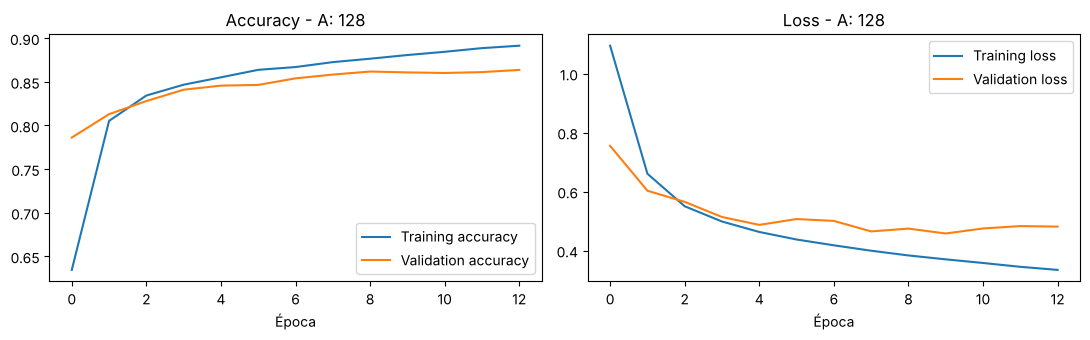

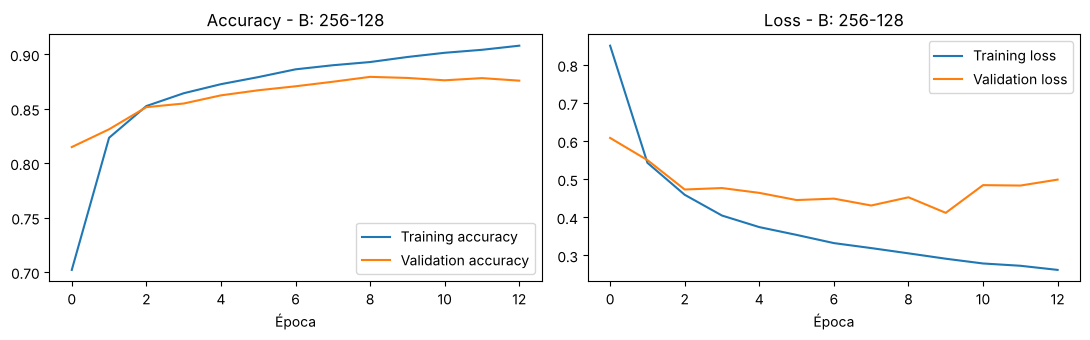

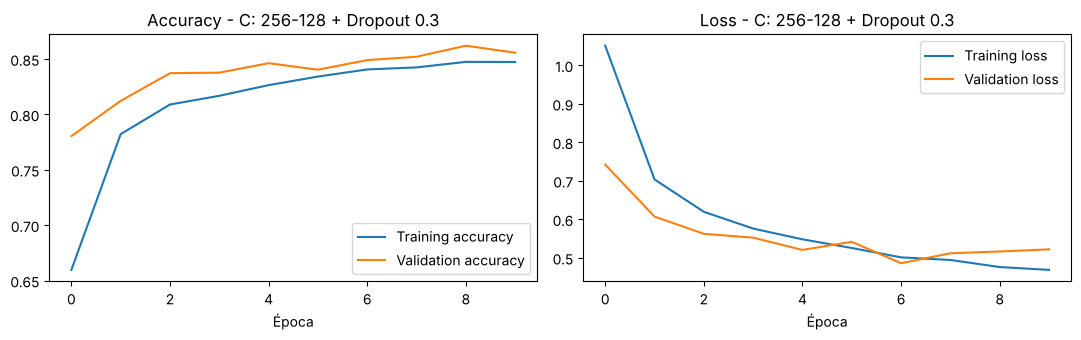

In [ ]:
for nombre, historia in historiales.items():
    plot_learning_curve(historia, titulo=f"- {nombre}")

## 8. Gráfica en 2D (espacio latente)
Se extrae la salida de la capa `rep_2d`: cada imagen queda reducida a **un punto en el plano**.
Si la red separó bien las clases, las prendas del mismo tipo se agrupan.

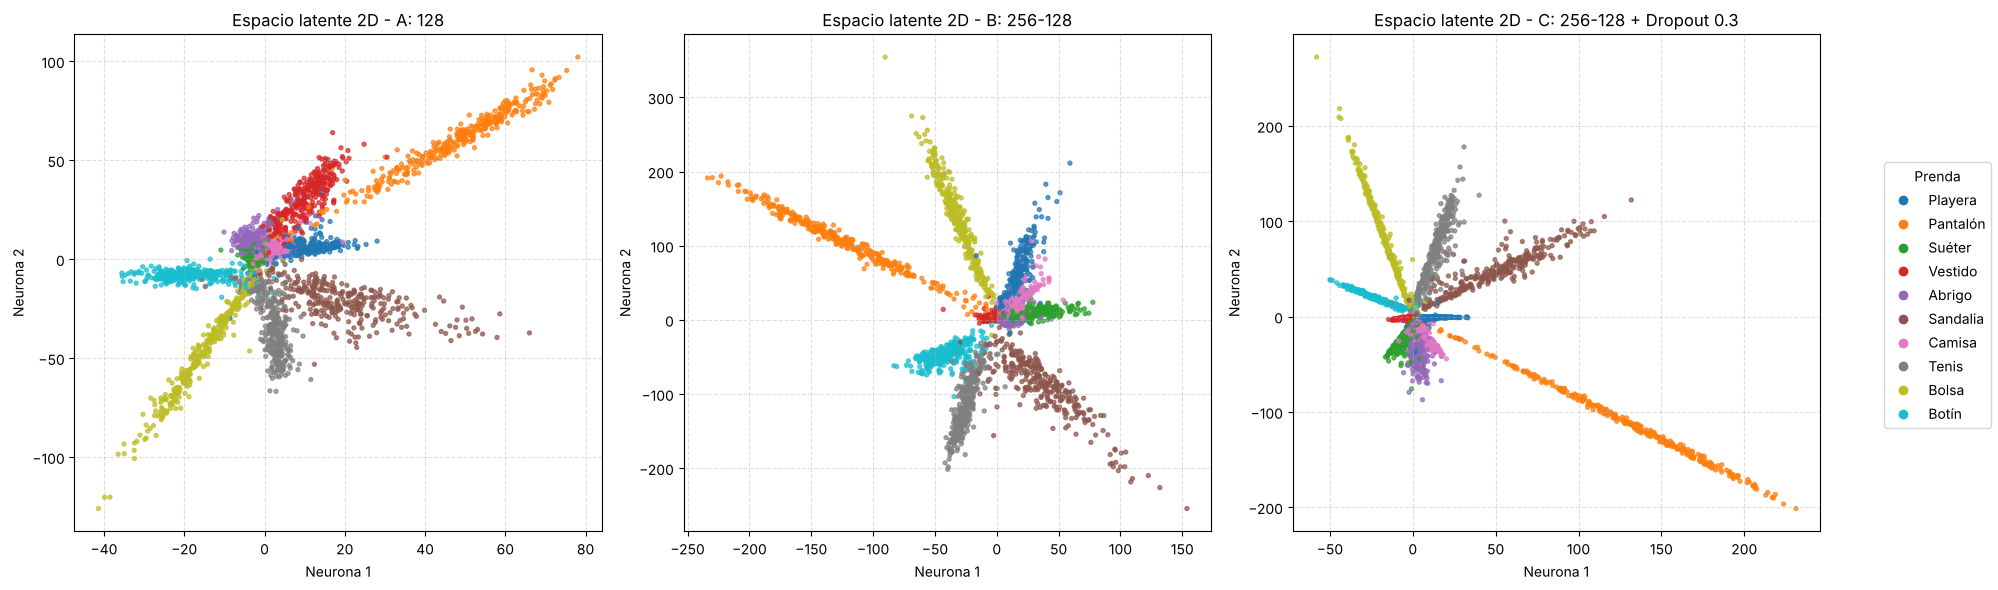

In [ ]:
def obtener_puntos_2d(modelo, ds, n_lotes=100):
    extractor = tf.keras.Model(inputs=modelo.inputs,
                               outputs=modelo.get_layer("rep_2d").output)
    subset = ds.take(n_lotes)  # 100 lotes x 32 = 3200 imágenes
    puntos = extractor.predict(subset.map(lambda x, y: x), verbose=0)
    etiquetas = np.concatenate([y.numpy() for _, y in subset])
    return puntos, etiquetas

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    puntos, etiquetas = obtener_puntos_2d(modelo, test_ds)
    sc = ax.scatter(puntos[:, 0], puntos[:, 1], c=etiquetas,
                    cmap="tab10", s=8, alpha=0.7)
    ax.set_title(f"Espacio latente 2D - {nombre}")
    ax.set_xlabel("Neurona 1"); ax.set_ylabel("Neurona 2")
    ax.grid(True, linestyle="--", alpha=0.4)

handles = [plt.Line2D([], [], marker="o", linestyle="", color=plt.cm.tab10(i / 9),
                      label=nombres_clases[i]) for i in range(10)]
fig.legend(handles=handles, loc="center right", title="Prenda")
plt.tight_layout(rect=[0, 0, 0.92, 1])
plt.show()

## 9. Matriz de confusión del mejor modelo

Mejor configuración (según accuracy en validación): B: 256-128


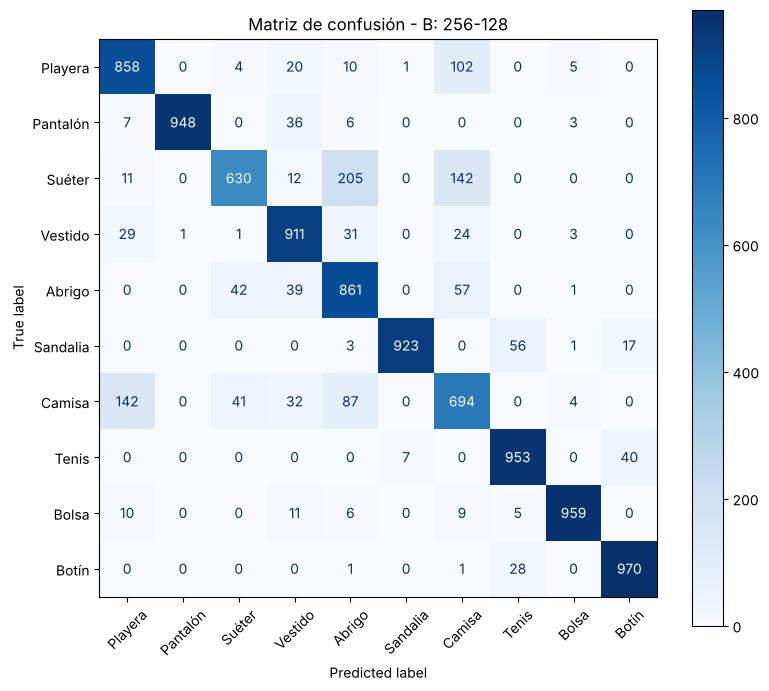

Suéter      0.630
Camisa      0.694
Playera     0.858
Abrigo      0.861
Vestido     0.911
Sandalia    0.923
Pantalón    0.948
Tenis       0.953
Bolsa       0.959
Botín       0.970
dtype: float64


In [ ]:
mejor = tabla["Accuracy validación"].idxmax()  # se elige con validación; test queda para el reporte final
print("Mejor configuración (según accuracy en validación):", mejor)

y_real = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(modelos[mejor].predict(test_ds.map(lambda x, y: x), verbose=0), axis=1)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    y_real, y_pred, display_labels=nombres_clases,
    cmap="Blues", ax=ax, xticks_rotation=45)
plt.title(f"Matriz de confusión - {mejor}")
plt.grid(False)
plt.show()

# Accuracy por clase
acc_por_clase = pd.Series(
    {nombres_clases[i]: (y_pred[y_real == i] == i).mean() for i in range(10)}
).sort_values()
print(acc_por_clase.round(3))

## 10. Conclusiones

| Configuración | Parámetros | Accuracy validación | Accuracy test |
|---|---|---|---|
| A: 128 | 100,768 | 0.8608 | 0.8501 |
| **B: 256-128** | 234,144 | **0.8783** | **0.8707** |
| C: 256-128 + Dropout 0.3 | 234,144 | 0.8490 | 0.8394 |

1. **La que mejor me funcionó fue la B (256 → 128).** Al meterle más neuronas y capas, la red tuvo más margen para aprender y me subió casi 2 puntos de accuracy en test comparado con la primera prueba (A).
2. **El Dropout de plano no me ayudó (C).** Como dejé la capa `rep_2d` con solo 2 neuronas, el modelo ya venía muy limitado y su problema no era memorizar de más, sino quedarse corto. De hecho, en esta prueba el accuracy de entrenamiento (0.84) me quedó hasta más bajo que el de validación porque el dropout estuvo apagando neuronas mientras entrenaba. Básicamente, castigué de más a una red que ya estaba apretada.
3. **Lo que noté en la gráfica 2D.** Los grupos salen como "rayos" desde el centro. Las prendas muy distintas como Pantalón, Tenis, Botín, Bolsa y Sandalia se separan súper bien, pero toda la ropa de arriba (Playera, Suéter, Abrigo y Camisa) se me amontona cerca del origen.
4. **La matriz de confusión me lo confirmó.** Donde más me falla el modelo es con Suéter y Camisa (andan en ≈ 63% y 69%), porque visualmente se parecen mucho a una Playera o un Abrigo. En cambio, las prendas con siluetas muy únicas pasan del 92% sin problema.
5. **Comprimir todo a 2 neuronas cuesta puntos.** Pasar de los 784 píxeles a solo 2 números me sirvió mucho para poder graficarlo, pero en el camino se pierde info útil. Si quitara ese cuello de botella, seguro sacaría mejor accuracy.
